# Model Evaluation, Calibration, and Threshold Economics

**What you'll learn**

- Split every classifier evaluation into three separate questions — *how well does it rank?*
  (ROC/PR), *are the probabilities real?* (calibration, proper scoring rules), and *what is the
  decision worth?* (threshold economics) — and why conflating them causes bad ship decisions.
- Why ROC-AUC and PR-AUC tell different stories about the *same* model at 1% prevalence,
  demonstrated on identical scores, plus the exact formula that links them.
- What "proper scoring rule" means, why log loss and Brier are proper and per-observation
  absolute error is not, and what improperness does to incentives.
- How random forests and (overfit) boosted trees miscalibrate, how to read reliability
  diagrams and ECE, and how to fix miscalibration with Platt scaling and isotonic regression
  on *properly held-out* data.
- How to turn a cost/benefit structure into an optimal threshold analytically
  ($t^* = c / \gamma V$ for a retention offer), verify it by sweep, and price the damage from
  miscalibration — including two models with *identical AUC* and wildly different profit.
- How to translate "reduce churn" into a target definition, an offline metric stack, a decision
  policy, and an online experiment — and why F1 at threshold 0.5 is almost never the answer.

**Why it matters in interviews**

- "Your model says 0.9 — what does that number mean?" and "ROC or PR curve here, and why?" are
  near-universal senior ML screening questions; shallow answers end interviews early.
- Case rounds love threshold questions ("offers cost \$10, a save is worth \$150 — who do you
  target?"): they test whether you can connect probabilities to money, which is the actual job.
- Calibration is the classic separator between candidates who have shipped decision-making
  systems (pricing, credit, retention, fraud) and candidates who have only ranked things.

## Setup

Everything runs on one simulated subscription-churn dataset with **known ground truth**: for
every customer we keep the true churn probability $p_i$ the labels were drawn from. That buys
us things no real dataset can offer: an oracle model to bound achievable performance, exact
Bayes floors for Brier score and log loss, and — crucially for the economics sections — the
ability to compute the *exact expected profit* of any targeting policy instead of a noisy
realized estimate.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.optimize import brentq
from scipy.special import expit, logit
from scipy.stats import rankdata

import xgboost as xgb
from sklearn.calibration import CalibratedClassifierCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.frozen import FrozenEstimator
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    brier_score_loss,
    f1_score,
    log_loss,
    precision_recall_curve,
    roc_auc_score,
    roc_curve,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

rng = np.random.default_rng(42)

plt.rcParams.update({
    "figure.figsize": (8, 4.5),
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
})

pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

## 1. Three questions every classifier evaluation must answer

"Is the model good?" is three different questions wearing one trench coat:

| Question | Property | Metrics | Invariant to… |
|---|---|---|---|
| Does it put churners above non-churners? | **Ranking** | ROC-AUC, PR-AUC, recall@k, lift | any strictly monotone rescaling of scores |
| When it says 0.30, do 30% churn? | **Calibration** | reliability diagram, ECE, calibration slope | nothing — the *values* matter |
| How much money does the policy built on it make? | **Decision quality** | expected profit/utility at the operating point | the metric *is* the point |

Proper scoring rules (log loss, Brier) sit across the first two rows: they reward ranking *and*
calibration at once, which is exactly why models are trained on them.

The failure mode this notebook attacks: teams report ranking metrics (AUC), then silently use
scores as if they were calibrated probabilities in a decision rule ("offer a discount if
churn risk > 25%"). Ranking metrics are blind to the score *values*, so nothing in the
dashboard warns you that the decision layer is broken. We will put an exact dollar figure on
that mistake in section 5.

## 2. Running example: subscription churn with known ground truth

One row = one subscriber at a monthly snapshot; the label is churn within the next 30 days,
base rate ≈ 10%. The generator hides realistic, *tree-learnable* structure inside the true
log-odds:

- a **price increase** hurts mostly customers *without* autopay (interaction);
- a steep **early-tenure** hazard that flattens after ~2 years (nonlinearity);
- a discrete jump for **dormant** accounts (`sessions_30d == 0`) on top of a smooth usage effect;
- "paying a lot, using little" (`spend × low sessions`) and premium-plan-but-idle interactions;
- a latent noise term — individual variation no model can see, so even the oracle's AUC is
  well below 1 (in real churn problems irreducible noise is the norm, not the exception; a
  suspiciously high AUC usually means leakage — see
  [02_leakage_validation.ipynb](02_leakage_validation.ipynb)).

We keep `p_true` for evaluation only — no model ever sees it.

In [2]:
N = 60_000


def simulate_churn(n, rng):
    """Subscription churn snapshot with known true churn probability per row."""
    plan = rng.choice(["basic", "pro", "premium"], size=n, p=[0.5, 0.35, 0.15])
    plan_mult = np.select(
        [plan == "basic", plan == "pro", plan == "premium"], [1.0, 1.8, 3.2]
    )
    monthly_spend = np.round(plan_mult * rng.lognormal(2.9, 0.35, n), 2)
    tenure_months = np.minimum(np.round(rng.gamma(1.6, 16, n)).astype(int), 120)
    sessions_30d = rng.poisson(rng.gamma(2.0, 4.0, n))
    support_tickets_90d = rng.poisson(0.35, n) + rng.binomial(1, 0.08, n) * rng.poisson(2.5, n)
    price_increase = rng.binomial(1, 0.30, n)
    autopay = rng.binomial(1, 0.55, n)
    pct_mobile = rng.beta(2, 2, n)

    spend_z = (np.log(monthly_spend) - 3.55) / 0.65
    latent = rng.normal(0, 0.55, n)  # unobservable individual variation
    z = (
        1.4 * price_increase * (1 - autopay)      # price shock bites without autopay
        + 0.25 * price_increase * autopay
        - 0.06 * np.minimum(tenure_months, 24)    # early-tenure hazard, then flat
        + 1.3 * (sessions_30d == 0)               # dormant accounts: discrete jump
        - 0.55 * np.log1p(sessions_30d)
        + 0.55 * np.minimum(support_tickets_90d, 4)
        + 1.0 * spend_z * (sessions_30d < 3)      # paying a lot, using little
        + 0.7 * (plan == "premium") * (sessions_30d < 5)
        - 0.45 * autopay
        + latent
    )
    b0 = brentq(lambda b: expit(b + z).mean() - 0.10, -12, 12)  # hit 10% base rate
    p_true = expit(b0 + z)
    churn = rng.binomial(1, p_true)
    return pd.DataFrame({
        "tenure_months": tenure_months, "monthly_spend": monthly_spend,
        "sessions_30d": sessions_30d, "support_tickets_90d": support_tickets_90d,
        "price_increase": price_increase, "autopay": autopay,
        "pct_mobile": pct_mobile, "plan": plan,
        "churn": churn, "p_true": p_true,
    })


df = simulate_churn(N, rng)
print(f"n = {len(df):,}   churn rate = {df['churn'].mean():.3f}   mean p_true = {df['p_true'].mean():.3f}")
print("p_true quartiles:", np.round(np.quantile(df["p_true"], [0.25, 0.5, 0.75, 0.99]), 3))
df.head()

n = 60,000   churn rate = 0.100   mean p_true = 0.100
p_true quartiles: [0.025 0.05  0.114 0.7  ]


,tenure_months,monthly_spend,sessions_30d,support_tickets_90d,price_increase,autopay,pct_mobile,plan,churn,p_true
0,12,43.1600,2,5,0,0,0.5118,pro,0,0.5071
1,31,12.7700,11,1,1,1,0.6898,basic,0,0.0342
2,30,140.8100,5,0,0,1,0.4831,premium,0,0.0170
3,3,22.1600,15,3,1,0,0.1042,pro,1,0.7187
4,2,25.9000,9,2,1,1,0.5534,basic,0,0.4095


### Three models, three splits

We use a **train / calibration / test** split (20k / 15k / 25k). The calibration set exists
because recalibration is *learning from data* and needs data the model has never touched —
same logic as any preprocessing-leakage argument
([02_leakage_validation.ipynb](02_leakage_validation.ipynb)). The test set stays untouched
until scoring.

The contenders: logistic regression on raw features (a strong, usually-calibrated baseline),
a default random forest, and a reasonably tuned XGBoost (see
[01_gradient_boosting_mastery.ipynb](01_gradient_boosting_mastery.ipynb) for how those knobs
were chosen).

In [3]:
X = pd.get_dummies(df.drop(columns=["churn", "p_true"]), columns=["plan"], drop_first=False)
y = df["churn"].to_numpy()
p_true = df["p_true"].to_numpy()

idx = rng.permutation(N)
i_tr, i_ca, i_te = idx[:20_000], idx[20_000:35_000], idx[35_000:]
X_tr, X_ca, X_te = X.iloc[i_tr], X.iloc[i_ca], X.iloc[i_te]
y_tr, y_ca, y_te = y[i_tr], y[i_ca], y[i_te]
p_te = p_true[i_te]  # oracle probabilities — evaluation only

lr = Pipeline([
    ("scale", StandardScaler()),
    ("lr", LogisticRegression(max_iter=2000)),
]).fit(X_tr, y_tr)

rf = RandomForestClassifier(n_estimators=200, n_jobs=2, random_state=42).fit(X_tr, y_tr)

xgb_clf = xgb.XGBClassifier(
    n_estimators=300, learning_rate=0.1, max_depth=5, subsample=0.9, colsample_bytree=0.9,
    eval_metric="logloss", tree_method="hist", random_state=42, n_jobs=2,
).fit(X_tr, y_tr)

scores = {
    "logreg": lr.predict_proba(X_te)[:, 1],
    "rf": rf.predict_proba(X_te)[:, 1],
    "xgb": xgb_clf.predict_proba(X_te)[:, 1],
    "oracle (p_true)": p_te,
}


def summarize(y_true, score_dict):
    rows = {}
    for name, s in score_dict.items():
        rows[name] = {
            "ROC-AUC": roc_auc_score(y_true, s),
            "PR-AUC": average_precision_score(y_true, s),
            "Brier": brier_score_loss(y_true, s),
            "log loss": log_loss(y_true, s),
        }
    return pd.DataFrame(rows).T


tbl = summarize(y_te, scores)
brier_floor = np.mean(p_te * (1 - p_te))
ll_floor = np.mean(-p_te * np.log(p_te) - (1 - p_te) * np.log(1 - p_te))
print(tbl.round(4))
print(f"\nBayes floors (expected score of the true probabilities): "
      f"Brier = {brier_floor:.4f}, log loss = {ll_floor:.4f}")
print(f"test prevalence = {y_te.mean():.4f}  (PR-AUC of a random ranker ≈ prevalence)")

                 ROC-AUC  PR-AUC  Brier  log loss
logreg            0.7510  0.3014 0.0817    0.2882
rf                0.7437  0.3201 0.0814    0.3466
xgb               0.7646  0.3455 0.0794    0.2831
oracle (p_true)   0.8157  0.4392 0.0728    0.2565

Bayes floors (expected score of the true probabilities): Brier = 0.0724, log loss = 0.2546
test prevalence = 0.1018  (PR-AUC of a random ranker ≈ prevalence)


Reading this table like a senior candidate:

- **XGBoost wins the ranking** (AUC 0.765 vs 0.751 for logistic regression, 0.744 for the
  forest): the DGP's interactions and thresholds are exactly what trees are for.
- **The oracle AUC is only 0.816.** The latent-noise term makes perfect discrimination
  impossible — our best model is ~0.05 AUC from the ceiling, not ~0.23 from "perfect".
  Knowing the ceiling exists changes how you spend your time (features vs tuning).
- **A first hint that ranking and probability quality are different things:** the random
  forest's Brier score (0.0814) is slightly *better* than logistic regression's (0.0817),
  yet its log loss is far *worse* (0.347 vs 0.288). The forest emits some probabilities of
  exactly 0.0 for customers who do churn; log loss punishes confident wrongness brutally
  (unboundedly, before clipping), Brier caps the damage at 1 per observation. Same model,
  two proper scores, opposite verdicts about the tails — we'll dissect this in section 4.

## 3. Metrics with purpose

### 3.1 Accuracy is broken at imbalance (and 0.5 is not a threshold, it's a default)

At a 10% base rate, "nobody ever churns" scores 90% accuracy. Model accuracy at the library
default threshold of 0.5 barely moves that number while quietly ignoring nearly all churners
— because with honest probabilities and a 10% base rate, *few customers should be above 0.5*.

In [4]:
majority_acc = 1 - y_te.mean()
rows = {"always 'no churn'": {"accuracy": majority_acc, "recall": 0.0, "flagged": 0}}
for name in ["logreg", "rf", "xgb"]:
    pred = scores[name] >= 0.5
    rows[f"{name} @ 0.5"] = {
        "accuracy": (pred == y_te).mean(),
        "recall": pred[y_te == 1].mean(),
        "flagged": int(pred.sum()),
    }
acc_tbl = pd.DataFrame(rows).T
print(acc_tbl.round(4))
print(f"\nCustomers with TRUE churn probability > 0.5: {(p_te > 0.5).mean():.2%} of the test set")

                   accuracy  recall  flagged
always 'no churn'    0.8982  0.0000   0.0000
logreg @ 0.5         0.8987  0.0318 150.0000
rf @ 0.5             0.9012  0.1191 530.0000
xgb @ 0.5            0.9023  0.1344 582.0000

Customers with TRUE churn probability > 0.5: 2.64% of the test set


The models look "accurate" and are operationally useless at this threshold: accuracy beats
the majority baseline by ~0.4pp at best, while recall runs 3% (logreg) to 13% (xgb) — the
policy ignores ~7 in 8 churners. Note the last line — even the *true* probabilities put only
~3% of customers above 0.5. **`.predict()` in sklearn/XGBoost is `predict_proba >= 0.5`**; at any real-world
prevalence, that default encodes a cost assumption nobody signed off on (FP cost = FN cost).
The threshold belongs to the *decision*, not the model — section 6.

### 3.2 ROC-AUC is a ranking statistic

The most useful mental model: **AUC = the probability that a uniformly random positive is
scored above a uniformly random negative** (ties count ½). It is the Mann–Whitney U statistic
rescaled — see the rank-test connection in
[../01_statistical_foundations/02_hypothesis_testing_beyond_basics.ipynb](../01_statistical_foundations/02_hypothesis_testing_beyond_basics.ipynb).
Three consequences fall out immediately:

1. AUC is invariant to any strictly monotone transform of scores — it cannot see calibration;
2. AUC does not depend on prevalence (it conditions on one positive, one negative);
3. AUC weights all score regions of the ranking, including the vast low-score region your
   decision will never touch.

Let's verify the interpretation numerically for XGBoost.

In [5]:
s = scores["xgb"]
pos, neg = s[y_te == 1], s[y_te == 0]

# exact: Mann–Whitney via ranks
r_all = rankdata(s)
auc_rank = (r_all[y_te == 1].sum() - len(pos) * (len(pos) + 1) / 2) / (len(pos) * len(neg))

# Monte Carlo: sample random (positive, negative) pairs
rng_mc = np.random.default_rng(11)
ii = rng_mc.integers(0, len(pos), 400_000)
jj = rng_mc.integers(0, len(neg), 400_000)
auc_mc = np.mean((pos[ii] > neg[jj]) + 0.5 * (pos[ii] == neg[jj]))

print(f"sklearn roc_auc_score:        {roc_auc_score(y_te, s):.4f}")
print(f"rank formula (Mann-Whitney):  {auc_rank:.4f}")
print(f"Monte Carlo random pairs:     {auc_mc:.4f}")

sklearn roc_auc_score:        0.7646
rank formula (Mann-Whitney):  0.7646
Monte Carlo random pairs:     0.7642


### 3.3 ROC vs PR: the same model at 10% and at 1% prevalence

The link between the two curves is one line of algebra. At a threshold with true-positive
rate TPR and false-positive rate FPR, at prevalence $\pi$:

$$\text{precision} = \frac{\pi \cdot \text{TPR}}{\pi \cdot \text{TPR} + (1-\pi)\cdot \text{FPR}}$$

TPR and FPR are *class-conditional* — they don't change when prevalence changes (assuming the
score distributions within each class stay fixed). Precision mixes the classes, so the
prevalence ratio $(1-\pi)/\pi$ multiplies the damage of every false positive. At $\pi = 1\%$
that multiplier is 99: even a good ranker drowns in false positives.

Experiment: take the **same XGBoost scores** on the test set, then build a rarer world by
keeping all negatives and subsampling positives to 1% prevalence. ROC-AUC should barely move;
PR-AUC should collapse. We also overlay the *theoretical* 1%-prevalence PR curve computed
from the 10% ROC curve with the formula above — no refitting, no resampling.

                 prevalence  ROC-AUC  PR-AUC  PR-AUC of random
natural (~10%)       0.1018   0.7646  0.3455            0.1018
subsampled (1%)      0.0100   0.7720  0.0734            0.0100


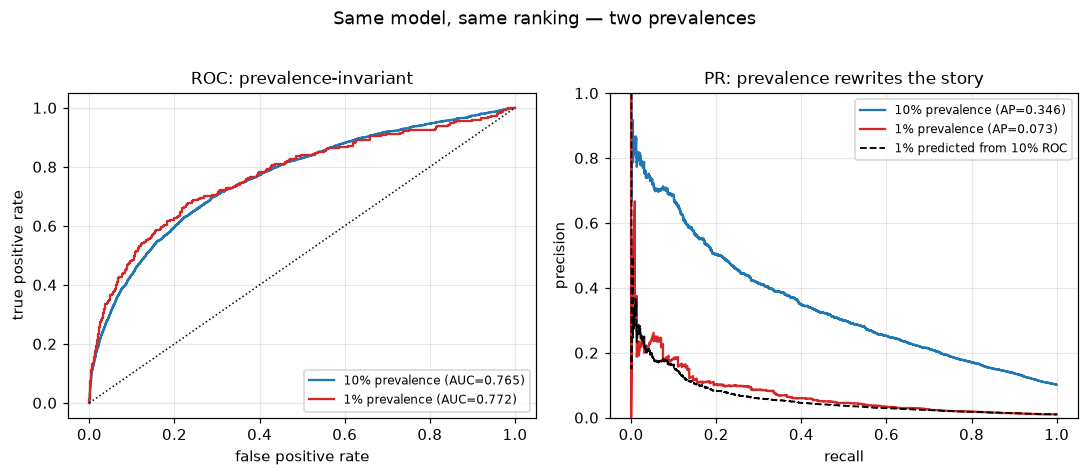

precision at ~50% recall, 10% prevalence: 0.299
precision at ~50% recall,  1% prevalence: 0.045


In [6]:
rng_sub = np.random.default_rng(7)
neg_idx = np.where(y_te == 0)[0]
pos_idx = np.where(y_te == 1)[0]
n_pos_1pct = int(round(len(neg_idx) * 0.01 / 0.99))
keep = np.concatenate([neg_idx, rng_sub.choice(pos_idx, n_pos_1pct, replace=False)])
y_1, s_1 = y_te[keep], s[keep]

res = pd.DataFrame({
    "prevalence": [y_te.mean(), y_1.mean()],
    "ROC-AUC": [roc_auc_score(y_te, s), roc_auc_score(y_1, s_1)],
    "PR-AUC": [average_precision_score(y_te, s), average_precision_score(y_1, s_1)],
    "PR-AUC of random": [y_te.mean(), y_1.mean()],
}, index=["natural (~10%)", "subsampled (1%)"])
print(res.round(4))

fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
for yy, ss, lab, c in [(y_te, s, "10% prevalence", "C0"), (y_1, s_1, "1% prevalence", "C3")]:
    fpr, tpr, _ = roc_curve(yy, ss)
    axes[0].plot(fpr, tpr, c, label=f"{lab} (AUC={roc_auc_score(yy, ss):.3f})")
    prec, rec, _ = precision_recall_curve(yy, ss)
    axes[1].plot(rec, prec, c, label=f"{lab} (AP={average_precision_score(yy, ss):.3f})")
axes[0].plot([0, 1], [0, 1], "k:", lw=1)
# theoretical PR curve at 1% prevalence, derived from the 10% ROC curve
fpr, tpr, _ = roc_curve(y_te, s)
mask = (tpr + fpr) > 0
prec_theory = 0.01 * tpr[mask] / (0.01 * tpr[mask] + 0.99 * fpr[mask])
axes[1].plot(tpr[mask], prec_theory, "k--", lw=1.2, label="1% predicted from 10% ROC")
axes[0].set(title="ROC: prevalence-invariant", xlabel="false positive rate", ylabel="true positive rate")
axes[1].set(title="PR: prevalence rewrites the story", xlabel="recall", ylabel="precision", ylim=(0, 1))
axes[0].legend(loc="lower right", fontsize=8)
axes[1].legend(loc="upper right", fontsize=8)
fig.suptitle("Same model, same ranking — two prevalences", y=1.02)
fig.tight_layout()
plt.show()

for yy, ss, lab in [(y_te, s, "10%"), (y_1, s_1, " 1%")]:
    prec, rec, _ = precision_recall_curve(yy, ss)
    i50 = np.argmin(np.abs(rec - 0.5))
    print(f"precision at ~50% recall, {lab} prevalence: {prec[i50]:.3f}")

ROC-AUC moved by noise (0.765 → 0.772, and only because the positive subsample is small);
PR-AUC crashed from ~0.35 to ~0.07, and precision at 50% recall fell from ~0.30 to ~0.05.
The dashed line shows this was *predictable*: the 1% PR curve is fully determined by the 10%
ROC curve plus the new prevalence. Same model, same ranking — a different **operating
reality**.

**When to use which (the senior answer):**

- **PR** when positives are rare *and* your decision lives in the top of the ranking (fraud
  review queues, alert triage): precision and recall are the quantities the ops team feels,
  and ROC-AUC's flattering invariance hides the false-positive flood. A model with 0.95
  ROC-AUC can be operationally useless at 0.1% prevalence. More in
  [04_imbalanced_fraud.ipynb](04_imbalanced_fraud.ipynb).
- **ROC** when you want a prevalence-portable summary of the ranker itself (compare across
  segments/time windows with different base rates), or when both error directions matter
  across the whole range.
- Two caveats worth volunteering: a random ranker's PR-AUC ≈ prevalence (so never compare
  PR-AUC across datasets with different base rates), and neither AUC evaluates the score
  *values* — a point most candidates miss and the next section makes precise.

### 3.4 Proper scoring rules: why log loss and Brier, specifically

A scoring rule $S(q, y)$ is **proper** if reporting the true probability minimizes expected
loss: $\mathbb{E}_{y \sim \text{Bern}(p)}\,S(q, y)$ is minimized at $q = p$ (strictly proper:
*uniquely* minimized). Log loss and Brier are strictly proper. Mean absolute error on
probabilities, $|y - q|$, is not — its expectation $p(1-q) + (1-p)q$ is *linear* in $q$, so
it is minimized by reporting 0 or 1. An improper score doesn't just measure badly, it
**rewards lying**: a model (or a forecaster paid on that score) does best by exaggerating.

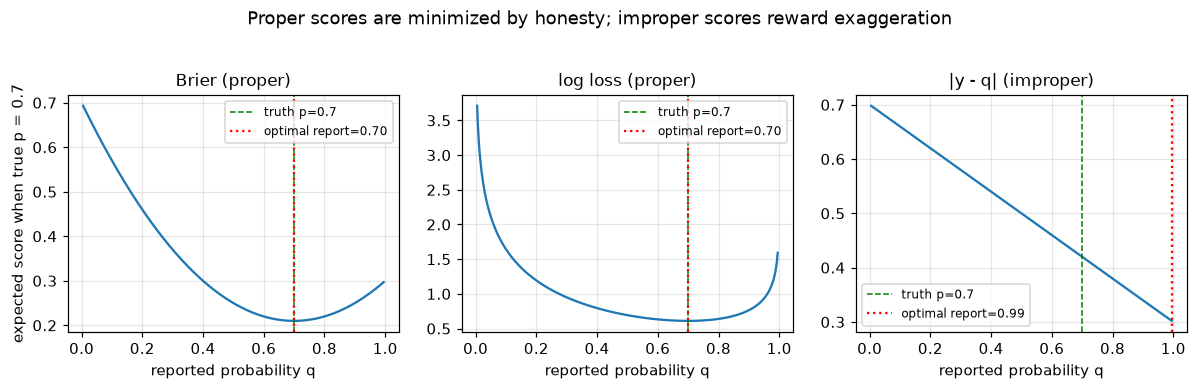

In [7]:
p0 = 0.7  # true probability of the event
q = np.linspace(0.005, 0.995, 400)
exp_brier = p0 * (1 - q) ** 2 + (1 - p0) * q**2
exp_logloss = -(p0 * np.log(q) + (1 - p0) * np.log(1 - q))
exp_mae = p0 * (1 - q) + (1 - p0) * q

fig, axes = plt.subplots(1, 3, figsize=(11, 3.4), sharex=True)
for ax, curve, name in zip(axes, [exp_brier, exp_logloss, exp_mae],
                           ["Brier (proper)", "log loss (proper)", "|y - q| (improper)"]):
    ax.plot(q, curve, "C0")
    q_min = q[np.argmin(curve)]
    ax.axvline(p0, color="green", ls="--", lw=1, label=f"truth p={p0}")
    ax.axvline(q_min, color="red", ls=":", lw=1.5, label=f"optimal report={q_min:.2f}")
    ax.set(title=name, xlabel="reported probability q")
    ax.legend(fontsize=8)
axes[0].set_ylabel(f"expected score when true p = {p0}")
fig.suptitle("Proper scores are minimized by honesty; improper scores reward exaggeration", y=1.03)
fig.tight_layout()
plt.show()

**Why properness matters in practice:**

- **Training.** Log loss *is* the training objective of logistic regression and (by default)
  XGBoost/LightGBM classifiers. Minimizing a proper score is what pushes fitted scores toward
  conditional probabilities in the first place. Train a model to maximize accuracy or F1
  directly and you get a hard classifier with no usable probability layer.
- **Model selection.** Selecting on a proper score can never favor a distorted-probability
  version of a model over the honest one; selecting on AUC alone can't tell them apart, and
  selecting on accuracy/F1 at a fixed threshold actively can.
- **The two proper scores weight errors differently.** Brier is bounded ([0,1] per
  observation) and gentle on tail errors; log loss explodes as $q \to 0$ under $y=1$. We saw
  exactly this above: the forest's hard zeros were nearly free under Brier and ruinous under
  log loss. If downstream decisions ride on small probabilities (credit, fraud), log loss's
  tail sensitivity is a feature, not a bug.

Simulation luxury: we computed the *Bayes floors* earlier — no model can beat
Brier ≈ 0.0724 / log loss ≈ 0.2546 (up to sampling noise: the oracle's realized test scores,
0.0728 / 0.2565, sit just above their own expectation) because that is the score of the
true probabilities themselves. Our best model sits at 0.0794 / 0.283: decomposition-wise,
most of the remaining Brier gap is *refinement* (features it can't see), not calibration —
which we can now check directly.

## 4. Calibration: are the probabilities real?

A model is **calibrated** if, among customers scored ~0.3, ~30% actually churn:
$\Pr(Y=1 \mid \hat p = q) = q$. Calibration says nothing about usefulness — predicting the
base rate 0.10 for everyone is perfectly calibrated and perfectly uninformative. You need
ranking *and* calibration (that combination is what proper scores measure jointly).

**Who miscalibrates, and why** (the classic reference is Niculescu-Mizil & Caruana 2005):

- **Logistic regression** minimizes log loss on a probability scale: near-calibrated by
  construction *if* the model isn't badly misspecified. (It can still be miscalibrated within
  segments its functional form can't express.)
- **Random forests** average vote fractions of deep, overfit trees. Historically that
  produces scores squashed *away* from 0 and 1; with modern fully-grown forests on noisy
  data you often see the opposite — leaves are pure, so scores get pushed *toward* 0/1,
  overconfident at both ends, including exact 0s. Either way: the reliability curve is bent,
  and the shape depends on hyperparameters, so you check, not assume.
- **Boosted trees**: AdaBoost-era boosting (exponential loss) was famously miscalibrated.
  Modern gradient boosting *trained on log loss* is optimizing a proper score, so a
  well-regularized, early-stopped XGBoost is often close to calibrated — but let it overfit
  and the raw margins grow without bound, pushing probabilities to the extremes. We'll show
  both regimes with the same library.

The diagnostic is the **reliability diagram**: bin test scores (we use quantile bins so every
bin has equal mass), plot mean predicted vs observed frequency.

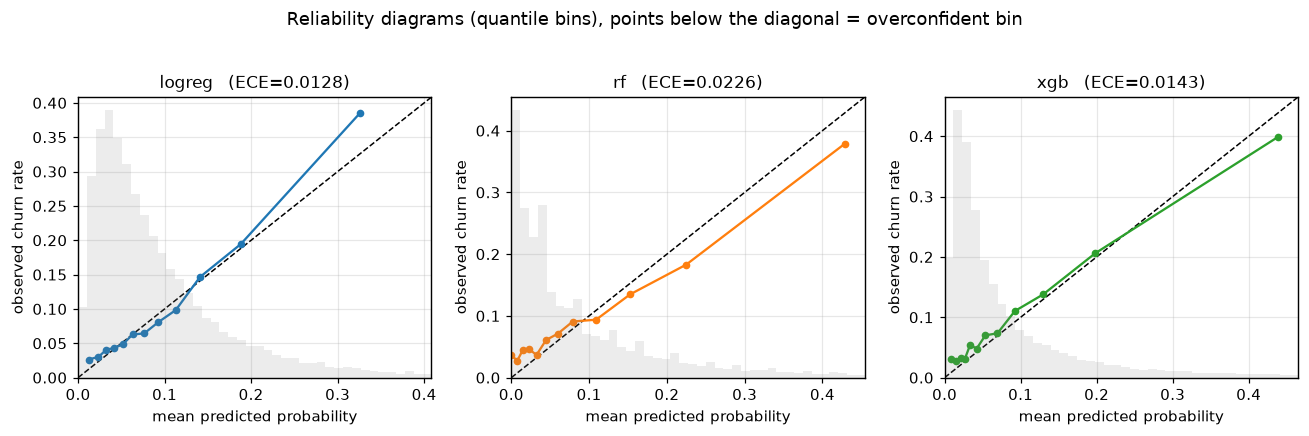

logreg   mean prediction = 0.0968  (prevalence 0.1018);  share of exact 0/1 scores = 0.0000
rf       mean prediction = 0.1006  (prevalence 0.1018);  share of exact 0/1 scores = 0.0471
xgb      mean prediction = 0.0940  (prevalence 0.1018);  share of exact 0/1 scores = 0.0000


In [8]:
def reliability_table(y_true, s_score, n_bins=10):
    """Quantile-binned reliability: (mean score, observed rate, count) per bin."""
    edges = np.quantile(s_score, np.linspace(0, 1, n_bins + 1))
    edges[0], edges[-1] = 0.0, 1.0
    b = np.clip(np.searchsorted(edges, s_score, side="right") - 1, 0, n_bins - 1)
    return np.array([
        (s_score[b == i].mean(), y_true[b == i].mean(), (b == i).sum())
        for i in range(n_bins) if (b == i).sum() > 0
    ])


def ece(y_true, s_score, n_bins=15, strategy="quantile"):
    """Expected calibration error: bin-weighted |mean score - observed rate|."""
    if strategy == "quantile":
        edges = np.quantile(s_score, np.linspace(0, 1, n_bins + 1))
        edges[0], edges[-1] = 0.0, 1.0
    else:  # equal-width
        edges = np.linspace(0, 1, n_bins + 1)
    b = np.clip(np.searchsorted(edges, s_score, side="right") - 1, 0, n_bins - 1)
    err = 0.0
    for i in range(n_bins):
        m = b == i
        if m.any():
            err += m.mean() * abs(s_score[m].mean() - y_true[m].mean())
    return err


def reliability_plot(ax, y_true, s_score, label, n_bins=12, color="C0"):
    r = reliability_table(y_true, s_score, n_bins)
    lim = 1.06 * max(r[:, 0].max(), r[:, 1].max())
    ax.plot([0, lim], [0, lim], "k--", lw=1)
    ax.plot(r[:, 0], r[:, 1], "o-", color=color, ms=4, label=label)
    ax.set(xlim=(0, lim), ylim=(0, lim), xlabel="mean predicted probability",
           ylabel="observed churn rate")
    ax.set_title(f"{label}   (ECE={ece(y_true, s_score):.4f})")
    # score distribution underlay
    ax2 = ax.twinx()
    ax2.hist(s_score, bins=40, range=(0, lim), alpha=0.15, color="gray")
    ax2.set_yticks([])
    ax2.grid(False)


fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
for ax, name, c in zip(axes, ["logreg", "rf", "xgb"], ["C0", "C1", "C2"]):
    reliability_plot(ax, y_te, scores[name], name, color=c)
fig.suptitle("Reliability diagrams (quantile bins), points below the diagonal = overconfident bin", y=1.03)
fig.tight_layout()
plt.show()

for name in ["logreg", "rf", "xgb"]:
    s_m = scores[name]
    print(f"{name:8s} mean prediction = {s_m.mean():.4f}  (prevalence {y_te.mean():.4f});  "
          f"share of exact 0/1 scores = {np.mean((s_m == 0) | (s_m == 1)):.4f}")

Logistic regression hugs the diagonal. The forest is the miscreant: it predicts *exactly
zero* for a chunk of the test set (customers whose observed churn rate is ~3–4%) and
overshoots at the top — overconfident at both ends, which is also why its log loss was
terrible. Tuned XGBoost is mildly overconfident at the low end but respectable.

Now the second boosting regime: same library, an overfit configuration (deeper trees, higher
learning rate, no stochastic regularization, 400 rounds, no early stopping).

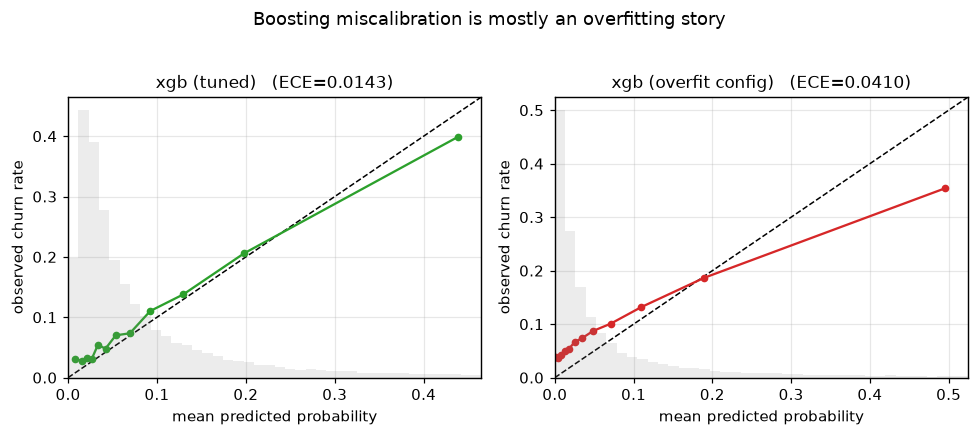

             ROC-AUC  Brier  log loss  ECE (q15)
xgb           0.7646 0.0794    0.2831     0.0143
xgb_overfit   0.7236 0.0860    0.3251     0.0410


In [9]:
xgb_overfit = xgb.XGBClassifier(
    n_estimators=400, learning_rate=0.2, max_depth=6, min_child_weight=1,
    eval_metric="logloss", tree_method="hist", random_state=42, n_jobs=2,
).fit(X_tr, y_tr)
scores["xgb_overfit"] = xgb_overfit.predict_proba(X_te)[:, 1]

fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
reliability_plot(axes[0], y_te, scores["xgb"], "xgb (tuned)", color="C2")
reliability_plot(axes[1], y_te, scores["xgb_overfit"], "xgb (overfit config)", color="C3")
fig.suptitle("Boosting miscalibration is mostly an overfitting story", y=1.03)
fig.tight_layout()
plt.show()

print(pd.DataFrame({
    n: {"ROC-AUC": roc_auc_score(y_te, scores[n]), "Brier": brier_score_loss(y_te, scores[n]),
        "log loss": log_loss(y_te, scores[n]), "ECE (q15)": ece(y_te, scores[n])}
    for n in ["xgb", "xgb_overfit"]
}).T.round(4))

The overfit config loses ranking (AUC 0.765 → 0.724) *and* becomes overconfident everywhere
— its bottom decile predicts ~0.001 where the observed rate is ~4%, its top bin ~0.49 where
the observed rate is ~0.35. Overfitting a
log-loss booster shows up as *probabilities pushed toward the extremes*, which is exactly
what early stopping on a validation set prevents.

### ECE in one number — handle with care

$$\text{ECE} = \sum_b \frac{n_b}{n}\,\bigl|\bar{\hat p}_b - \bar y_b\bigr|$$

It's the bin-weighted average gap in the reliability diagram — useful for dashboards and
comparisons, but it depends on the binning scheme (shown in Pitfalls) and, like any
average, it can hide compensating errors. Report it *with* the diagram, not instead of it.

In [10]:
ece_tbl = pd.DataFrame({
    name: {
        "ECE quantile-15": ece(y_te, scores[name], 15, "quantile"),
        "ECE equal-width-10": ece(y_te, scores[name], 10, "width"),
    }
    for name in ["logreg", "rf", "xgb", "xgb_overfit"]
}).T
print(ece_tbl.round(4))

             ECE quantile-15  ECE equal-width-10
logreg                0.0128              0.0065
rf                    0.0226              0.0226
xgb                   0.0143              0.0149
xgb_overfit           0.0410              0.0424


### Recalibration: Platt scaling and isotonic regression

Both learn a monotone map from raw score to probability on **held-out data** (our calibration
set), then apply it everywhere:

- **Platt scaling ("sigmoid")** fits a 2-parameter logistic regression on the score's logit:
  $q = \sigma(a \cdot \text{logit}(s) + b)$ (sklearn fits $\sigma(a s + b)$ on the raw score).
  Parametric, sample-efficient (works with a few hundred points), but it *assumes the
  distortion is sigmoid-shaped*. If it isn't, Platt can make things worse — watch below.
- **Isotonic regression** fits a nonparametric, monotone step function — flexible enough for
  any monotone distortion, needs more data (rule of thumb: ≥ ~1000 calibration points), and
  produces ties (many inputs map to one output value), which can shave a hair off AUC.

Mechanically we wrap each fitted model in `FrozenEstimator` so `CalibratedClassifierCV`
fits *only* the calibrator on the calibration set (this replaces the deprecated
`cv="prefit"`). If you can't afford a dedicated calibration split, use
`CalibratedClassifierCV(model, cv=5)` which cross-fits calibrators inside training folds —
what you must *never* do is calibrate on data the model was trained on (Pitfalls).

In [11]:
recal_rows = {}
cal_scores = {}
for name, model in [("rf", rf), ("xgb", xgb_clf), ("xgb_overfit", xgb_overfit)]:
    s_raw = scores[name]
    recal_rows[f"{name} raw"] = {
        "ROC-AUC": roc_auc_score(y_te, s_raw), "Brier": brier_score_loss(y_te, s_raw),
        "log loss": log_loss(y_te, s_raw), "ECE": ece(y_te, s_raw),
    }
    for method in ["sigmoid", "isotonic"]:
        cc = CalibratedClassifierCV(FrozenEstimator(model), method=method).fit(X_ca, y_ca)
        s_cal = cc.predict_proba(X_te)[:, 1]
        cal_scores[(name, method)] = s_cal
        recal_rows[f"{name} + {method}"] = {
            "ROC-AUC": roc_auc_score(y_te, s_cal), "Brier": brier_score_loss(y_te, s_cal),
            "log loss": log_loss(y_te, s_cal), "ECE": ece(y_te, s_cal),
        }
print(pd.DataFrame(recal_rows).T.round(4))

                        ROC-AUC  Brier  log loss    ECE
rf raw                   0.7437 0.0814    0.3466 0.0226
rf + sigmoid             0.7437 0.0811    0.2886 0.0144
rf + isotonic            0.7429 0.0811    0.2878 0.0081
xgb raw                  0.7646 0.0794    0.2831 0.0143
xgb + sigmoid            0.7646 0.0801    0.2851 0.0232
xgb + isotonic           0.7642 0.0793    0.2833 0.0066
xgb_overfit raw          0.7236 0.0860    0.3251 0.0410
xgb_overfit + sigmoid    0.7236 0.0836    0.2983 0.0220
xgb_overfit + isotonic   0.7229 0.0829    0.2944 0.0058


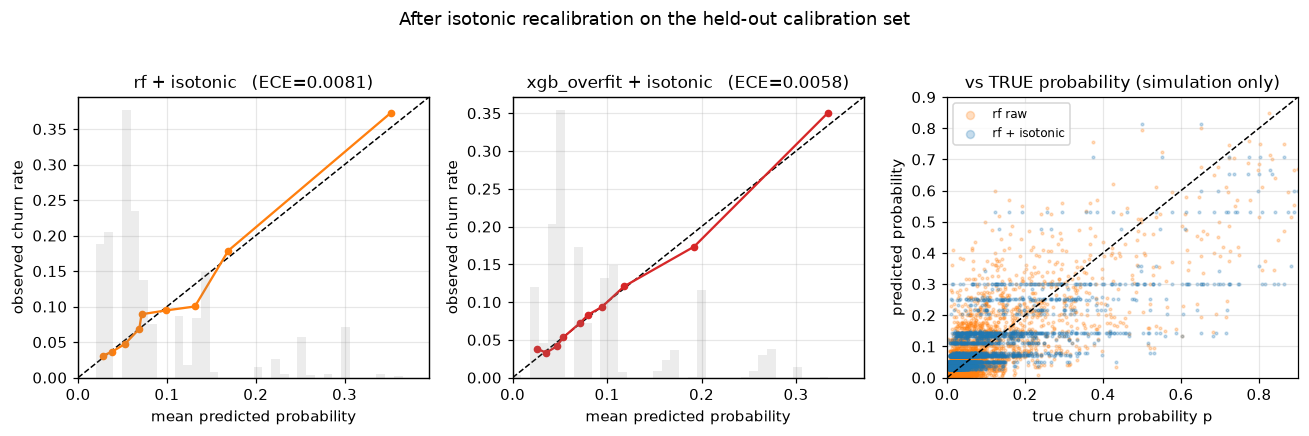

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
reliability_plot(axes[0], y_te, cal_scores[("rf", "isotonic")], "rf + isotonic", color="C1")
reliability_plot(axes[1], y_te, cal_scores[("xgb_overfit", "isotonic")], "xgb_overfit + isotonic", color="C3")
# simulation luxury: compare predictions to the TRUE probabilities
rng_plot = np.random.default_rng(5)
show = rng_plot.choice(len(p_te), 3000, replace=False)
axes[2].scatter(p_te[show], scores["rf"][show], s=3, alpha=0.25, color="C1", label="rf raw")
axes[2].scatter(p_te[show], cal_scores[("rf", "isotonic")][show], s=3, alpha=0.25,
                color="C0", label="rf + isotonic")
axes[2].plot([0, 1], [0, 1], "k--", lw=1)
axes[2].set(title="vs TRUE probability (simulation only)", xlabel="true churn probability p",
            ylabel="predicted probability", xlim=(0, 0.9), ylim=(0, 0.9))
axes[2].legend(fontsize=8, markerscale=3)
fig.suptitle("After isotonic recalibration on the held-out calibration set", y=1.03)
fig.tight_layout()
plt.show()

What the table should teach you:

- **Isotonic fixes both offenders** — RF's ECE drops ~0.023 → ~0.008 and its log loss falls
  from 0.347 to 0.288 (the exact-zero pathology is gone); the overfit XGBoost's ECE drops
  ~0.041 → ~0.006. **Ranking is preserved**: AUC changes only in the 3rd–4th decimal (isotonic's
  ties), because a monotone map can't reorder scores.
- **Platt helps RF but *hurts* the tuned XGBoost** (ECE 0.014 → 0.023): the tuned model's
  distortion isn't sigmoid-shaped, so forcing a 2-parameter sigmoid through it moves
  probabilities the wrong way in places. Nonparametric isotonic, with 15k calibration points,
  wins across the board here. With a few hundred calibration points the ranking would flip.
- **Recalibration cannot buy discrimination.** The recalibrated forest still ranks worse than
  tuned XGBoost. Calibration repairs the probability scale; only better features/models
  repair the ranking. (Also note the scatter: even calibrated, individual predictions spread
  widely around the truth — calibration is a property of *averages within score bins*, not a
  per-customer accuracy guarantee.)

## 5. Calibration is money: retention offer targeting

Now the payoff. The retention team can send a save offer to any customer:

- the offer costs $c = \$10$ per targeted customer (incentive + contact cost),
- a targeted *would-churner* is saved with probability $\gamma = 0.30$,
- a save retains $V = \$150$ of future margin (LTV logic:
  [../08_product_analytics/03_ltv_modeling.ipynb](../08_product_analytics/03_ltv_modeling.ipynb)).

Expected value of targeting a customer with churn probability $p$:

$$\text{EV}(p) = \gamma V p - c = 45p - 10
\quad\Rightarrow\quad \text{target iff } p > \frac{c}{\gamma V} = \frac{10}{45} \approx 0.222$$

This "plug the number into the formula" step is where calibration stops being aesthetic:
**the rule consumes probability *values*, not ranks.** Because we simulated the data, we can
score any policy by its *exact* expected profit, $\sum_{i\,\text{targeted}} (45\,p_i - 10)$
with the true $p_i$ — alongside the realized profit on sampled outcomes.

In [13]:
C_OFFER, GAMMA, V_SAVE = 10.0, 0.30, 150.0
GV = GAMMA * V_SAVE            # expected save value of targeting a certain churner = $45
T_STAR = C_OFFER / GV          # optimal threshold on TRUE probability = 0.2222
print(f"analytic threshold t* = {T_STAR:.4f}")


def expected_profit(s_decision, thresh):
    """Exact expected profit of 'target if score >= thresh', using true probabilities."""
    target = s_decision >= thresh
    return np.sum(GV * p_te[target] - C_OFFER)


def realized_profit(s_decision, thresh):
    """Profit using sampled outcomes (what an A/B readout would estimate)."""
    target = s_decision >= thresh
    return np.sum(GV * y_te[target] - C_OFFER)


policy_scores = {
    "target nobody": np.zeros_like(p_te),
    "target everybody": np.ones_like(p_te),
    "oracle (true p)": p_te,
    "logreg raw": scores["logreg"],
    "rf raw": scores["rf"],
    "rf + isotonic": cal_scores[("rf", "isotonic")],
    "xgb raw": scores["xgb"],
    "xgb + isotonic": cal_scores[("xgb", "isotonic")],
}
profit_tbl = pd.DataFrame({
    name: {
        "n targeted": int((sc >= T_STAR).sum()),
        "expected profit ($)": expected_profit(sc, T_STAR),
        "realized profit ($)": realized_profit(sc, T_STAR),
    }
    for name, sc in policy_scores.items()
}).T
profit_tbl["ROC-AUC"] = [np.nan, np.nan] + [
    roc_auc_score(y_te, policy_scores[k]) for k in list(policy_scores)[2:]
]
print(profit_tbl.round(2))

analytic threshold t* = 0.2222
                  n targeted  expected profit ($)  realized profit ($)  ROC-AUC
target nobody         0.0000               0.0000               0.0000      NaN
target everybody 25,000.0000        -137,731.4800        -135,475.0000      NaN
oracle (true p)   2,905.0000          23,434.0100          24,950.0000   0.8200
logreg raw        2,126.0000          13,440.8200          15,460.0000   0.7500
rf raw            3,130.0000          12,934.4800          13,565.0000   0.7400
rf + isotonic     2,551.0000          13,470.9500          14,495.0000   0.7400
xgb raw           2,596.0000          15,728.5500          17,285.0000   0.7600
xgb + isotonic    2,767.0000          15,595.8900          17,150.0000   0.7600


Reading the table (25,000 test customers):

- **Blanket targeting is a bonfire** (≈ −\$138k): the average customer's churn probability
  (0.10) is far below 0.222, so most offers are wasted. "Send everyone a discount" fails not
  because discounts don't work but because expected value per send is negative.
- The **oracle** makes ≈ \$23.4k — the ceiling given these economics.
- **Calibrated XGBoost captures ≈ \$15.6k**, about two-thirds of the ceiling; the gap is
  ranking noise (AUC 0.76 vs 0.82), not miscalibration.
- **The raw forest targets 3,130 customers where its isotonic version targets 2,551, and
  leaves ≈ \$540 on the table** — identical model, near-identical AUC, different probability
  values → a different (worse) targeting set. That gap is the pure price of miscalibration,
  no ranking metric can see it, and it is *mild* here only because the forest's distortion
  happens to be small near $t^* = 0.222$; the distorted-XGBoost demo next puts the same
  failure on steroids.
- Realized and expected profit agree within sampling noise, but notice how much smoother the
  expected column is — in real life you only get the noisy one, via experiments (section 7).

### Same AUC, different money

The cleanest way to see that AUC cannot protect you: take the calibrated XGBoost scores and
apply strictly monotone distortions, $q = \sigma(a \cdot \text{logit}(p))$ with $a = 2.5$
(overconfident) and $a = 0.4$ (underconfident). Monotone ⇒ **identical ranking ⇒ identical
ROC-AUC, to every decimal.** Then run the same business rule "target if score ≥ 0.222".

                        ROC-AUC    ECE  n targeted @ 0.222  expected profit ($)
calibrated               0.7642 0.0066          2,767.0000          15,595.8944
overconfident (a=2.5)    0.7642 0.0758            430.0000           7,507.7480
underconfident (a=0.4)   0.7642 0.1700         18,213.0000         -78,897.6184


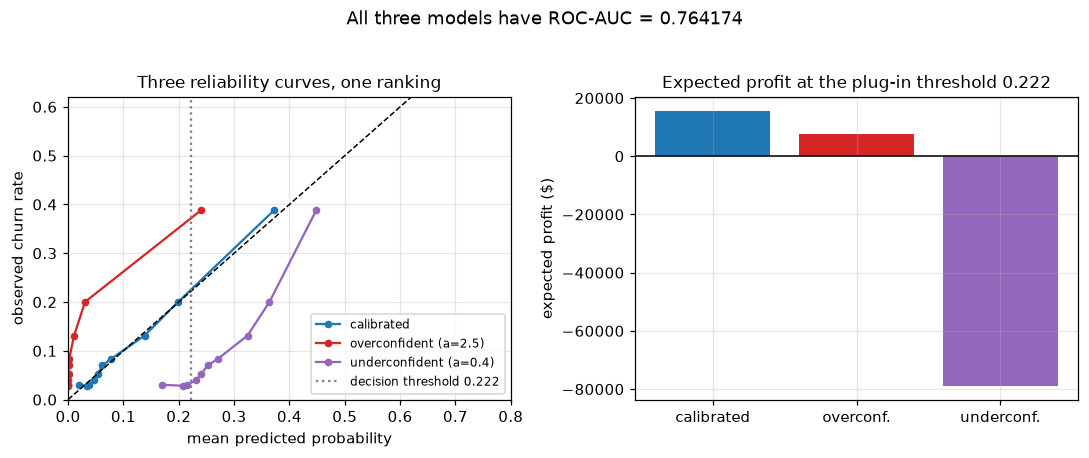

In [14]:
p_hat = np.clip(cal_scores[("xgb", "isotonic")], 1e-6, 1 - 1e-6)
variants = {
    "calibrated": p_hat,
    "overconfident (a=2.5)": expit(2.5 * logit(p_hat)),
    "underconfident (a=0.4)": expit(0.4 * logit(p_hat)),
}
same_auc = pd.DataFrame({
    name: {
        "ROC-AUC": roc_auc_score(y_te, v),
        "ECE": ece(y_te, v),
        "n targeted @ 0.222": int((v >= T_STAR).sum()),
        "expected profit ($)": expected_profit(v, T_STAR),
    }
    for name, v in variants.items()
}).T
print(same_auc.round(6))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for (name, v), c in zip(variants.items(), ["C0", "C3", "C4"]):
    r = reliability_table(y_te, v, 12)
    axes[0].plot(r[:, 0], r[:, 1], "o-", ms=4, color=c, label=name)
axes[0].plot([0, 0.8], [0, 0.8], "k--", lw=1)
axes[0].axvline(T_STAR, color="gray", ls=":", label="decision threshold 0.222")
axes[0].set(title="Three reliability curves, one ranking", xlabel="mean predicted probability",
            ylabel="observed churn rate", xlim=(0, 0.8), ylim=(0, 0.62))
axes[0].legend(fontsize=8)
profits = [same_auc.loc[k, "expected profit ($)"] for k in variants]
axes[1].bar(range(3), profits, color=["C0", "C3", "C4"])
axes[1].set_xticks(range(3), ["calibrated", "overconf.", "underconf."])
axes[1].axhline(0, color="k", lw=1)
axes[1].set(title=f"Expected profit at the plug-in threshold {T_STAR:.3f}",
            ylabel="expected profit ($)")
fig.suptitle(f"All three models have ROC-AUC = {roc_auc_score(y_te, p_hat):.6f}", y=1.03)
fig.tight_layout()
plt.show()

Three models, **byte-identical AUC**, and the plug-in policy earns ≈ \$15.6k, ≈ \$7.5k, and
≈ −\$79k. The direction of the damage is worth internalizing:

- The **overconfident** model squashes mid-risk scores toward 0 (everything below its 0.5
  pivot deflates), so customers with true risk 0.22–0.5 fall under the threshold: it targets
  only 430 customers and *misses* most profitable offers. Quietly unprofitable — under-spend.
- The **underconfident** model inflates low scores toward 0.5, so it targets 18k customers,
  most with true risk far below break-even: catastrophic over-spend. This is exactly what
  happens when someone trains with `class_weight="balanced"` (or on an up/down-sampled set)
  and forgets that the scores are no longer probabilities — see Pitfalls.

In production you won't get a labeled "true p" column — you'd see this as an offer budget
that mysteriously under- or over-spends against plan while the AUC dashboard glows green.

## 6. Threshold economics

### 6.1 The optimal threshold is a property of the cost matrix, not the model

General decision rule with a utility for each cell (act = target, class = churner):

| | churner ($p$) | non-churner ($1-p$) |
|---|---|---|
| **target** | $U_{TP}$ | $U_{FP}$ |
| **don't** | $U_{FN}$ | $U_{TN}$ |

Target iff $p\,U_{TP} + (1-p)\,U_{FP} \;>\; p\,U_{FN} + (1-p)\,U_{TN}$, i.e.

$$p \;>\; t^* = \frac{U_{TN} - U_{FP}}{(U_{TN} - U_{FP}) + (U_{TP} - U_{FN})}.$$

Our retention case is the special case $U_{TP} = \gamma V - c$, $U_{FP} = -c$,
$U_{FN} = U_{TN} = 0$, which gives $t^* = c/\gamma V = 0.222$. Notes a senior candidate
should volunteer:

- $t^*$ **contains no model quantities.** Models don't have thresholds; *decisions* do. When
  the economics change (offer cost doubles), the threshold moves with **zero retraining** —
  *if* the probabilities are calibrated.
- The formula assumes you may target everyone above $t^*$. With a **capacity constraint**
  (call center can make 1,500 calls), the policy becomes top-$k$ by score and only *ranking*
  matters — exercise 1 makes this precise.
- With uncalibrated scores you can still salvage a threshold *empirically* — sweep candidate
  thresholds on held-out labeled data and pick the profit-maximizing one. Let's do both.

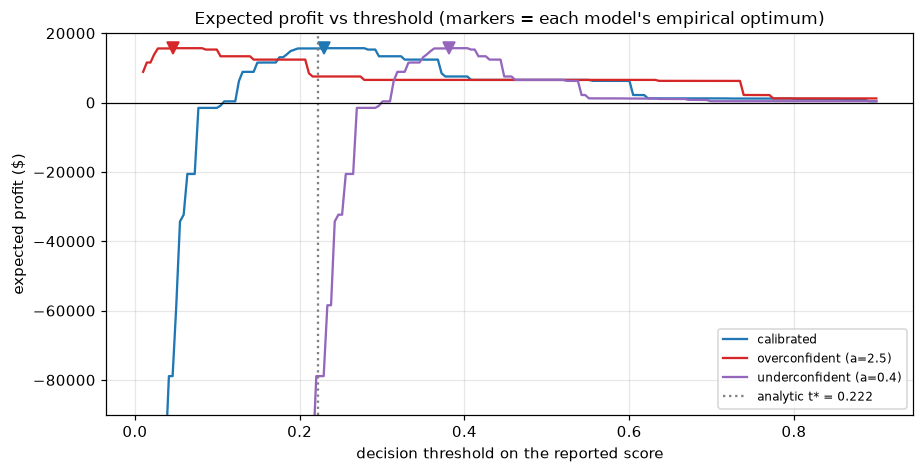

calibrated               best threshold = 0.229   profit at best =    15,667   profit at plug-in t* =    15,596
overconfident (a=2.5)    best threshold = 0.046   profit at best =    15,667   profit at plug-in t* =     7,508
underconfident (a=0.4)   best threshold = 0.381   profit at best =    15,667   profit at plug-in t* =   -78,898


In [15]:
thresholds = np.linspace(0.01, 0.9, 200)
sweep = {name: np.array([expected_profit(v, t) for t in thresholds])
         for name, v in variants.items()}

fig, ax = plt.subplots(figsize=(8.5, 4.4))
for (name, prof), c in zip(sweep.items(), ["C0", "C3", "C4"]):
    ax.plot(thresholds, prof, color=c, label=name)
    t_best = thresholds[np.argmax(prof)]
    ax.plot(t_best, prof.max(), "v", color=c, ms=8)
ax.axvline(T_STAR, color="gray", ls=":", lw=1.5, label=f"analytic t* = {T_STAR:.3f}")
ax.axhline(0, color="k", lw=0.8)
ax.set(title="Expected profit vs threshold (markers = each model's empirical optimum)",
       xlabel="decision threshold on the reported score", ylabel="expected profit ($)",
       ylim=(-90_000, 20_000))
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

for name, prof in sweep.items():
    t_best = thresholds[np.argmax(prof)]
    print(f"{name:24s} best threshold = {t_best:.3f}   profit at best = {prof.max():>9,.0f}   "
          f"profit at plug-in t* = {expected_profit(variants[name], T_STAR):>9,.0f}")

Two lessons in one plot:

- For the **calibrated** model the empirical optimum lands at ≈ 0.23, on top of the analytic
  $t^* = 0.222$ — theory and sweep agree, and the curve is *flat near the optimum* (being a
  cent off the perfect threshold costs almost nothing; being miscalibrated costs a lot).
- All three curves reach the **same maximum** (~\$15.7k): a monotone distortion doesn't
  destroy the profit frontier, it just *relabels the x-axis* (the over/underconfident optima
  sit at 0.05 and 0.38). The sweep can rescue a miscalibrated model — at the cost of a
  labeled sweep dataset, per decision, redone every time economics change or scores drift.
  Calibration is what makes thresholds *portable*: $t^*$ becomes a formula, changing $c$ or
  $V$ is arithmetic, and one probability model can serve many decision rules at once.

### 6.2 Why F1 is rarely the business answer

F1 is the harmonic mean of precision and recall at a threshold. Three strikes:

1. It **ignores true negatives entirely** — fine for retrieval, absurd for decisions where
   leaving people alone has value;
2. it implicitly prices a false positive and a false negative at a fixed exchange rate that
   (unlike $F_\beta$ with a justified $\beta$) nobody derived from the business;
3. it is threshold-dependent *and* prevalence-dependent, so "we optimized F1" answers a
   question no stakeholder asked.

F1-optimal threshold = 0.184  (max F1 = 0.376) — blind to economics

                          profit @ analytic t*  profit @ F1-optimal t
econ A: c=$10 (t*=0.222)           15,596.0000            13,880.0000
econ B: c=$25 (t*=0.556)            1,348.0000           -43,825.0000


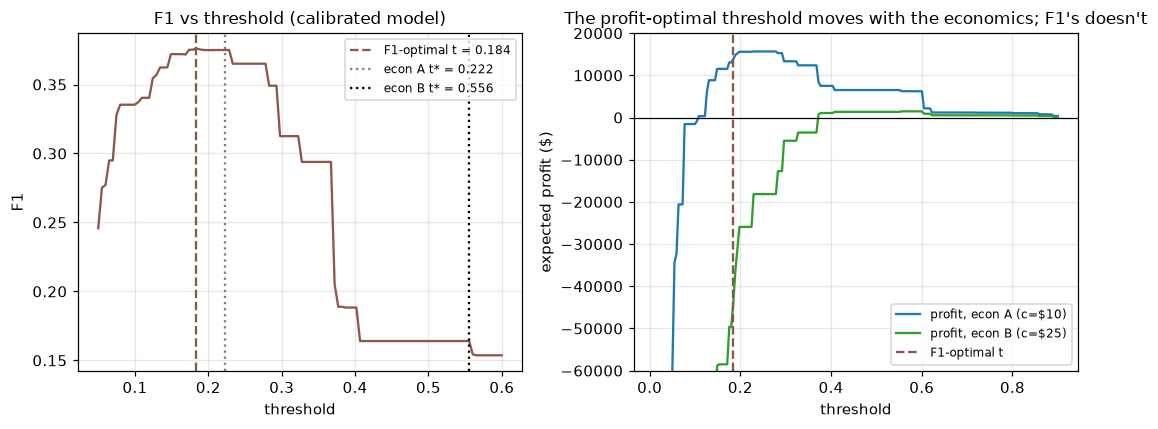

In [16]:
f1_grid = np.linspace(0.05, 0.6, 112)
f1_vals = np.array([f1_score(y_te, p_hat >= t, zero_division=0) for t in f1_grid])
t_f1 = f1_grid[np.argmax(f1_vals)]

# alternative economics: pricier offer (c=$25), same save value
C2 = 25.0
t_star2 = C2 / GV


def expected_profit2(s_decision, thresh):
    target = s_decision >= thresh
    return np.sum(GV * p_te[target] - C2)


cmp = pd.DataFrame({
    "econ A: c=$10 (t*=0.222)": {
        "profit @ analytic t*": expected_profit(p_hat, T_STAR),
        "profit @ F1-optimal t": expected_profit(p_hat, t_f1),
    },
    f"econ B: c=$25 (t*={t_star2:.3f})": {
        "profit @ analytic t*": expected_profit2(p_hat, t_star2),
        "profit @ F1-optimal t": expected_profit2(p_hat, t_f1),
    },
}).T
print(f"F1-optimal threshold = {t_f1:.3f}  (max F1 = {f1_vals.max():.3f}) — blind to economics\n")
print(cmp.round(0))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(f1_grid, f1_vals, "C5")
axes[0].axvline(t_f1, color="C5", ls="--", label=f"F1-optimal t = {t_f1:.3f}")
axes[0].axvline(T_STAR, color="gray", ls=":", label=f"econ A t* = {T_STAR:.3f}")
axes[0].axvline(t_star2, color="k", ls=":", label=f"econ B t* = {t_star2:.3f}")
axes[0].set(title="F1 vs threshold (calibrated model)", xlabel="threshold", ylabel="F1")
axes[0].legend(fontsize=8)
axes[1].plot(thresholds, sweep["calibrated"], "C0", label="profit, econ A (c=$10)")
axes[1].plot(thresholds, [expected_profit2(p_hat, t) for t in thresholds], "C2",
             label="profit, econ B (c=$25)")
axes[1].axvline(t_f1, color="C5", ls="--", label="F1-optimal t")
axes[1].axhline(0, color="k", lw=0.8)
axes[1].set(title="The profit-optimal threshold moves with the economics; F1's doesn't",
            xlabel="threshold", ylabel="expected profit ($)", ylim=(-60_000, 20_000))
axes[1].legend(fontsize=8)
fig.tight_layout()
plt.show()

Under economics A the F1 threshold (0.184) quietly costs ≈ \$1.7k vs the analytic optimum
(~11% of the achievable profit). Change the offer cost to \$25 — threshold should move to
0.556 — and the F1-optimal threshold *doesn't move* (it knows nothing about costs): the same
policy now **loses ≈ \$44k** while the correct threshold still makes money. If a stakeholder
insists on a single threshold metric, ask for the cost matrix first; if they can't produce
one, that conversation — not the metric — is the actual work. (When costs are genuinely
unknowable, curves and top-$k$ tables beat any single-threshold summary.)

## 7. From "reduce churn" to a metric stack

The business asks: *"reduce churn."* The senior translation runs through four layers, each
with its own metric — and confusing the layers is how projects fail:

| Layer | Artifact | Metric(s) | Owner of the failure mode |
|---|---|---|---|
| Target | "churn = no active subscription 30 days after snapshot date" — observable, leak-free ([02_leakage_validation.ipynb](02_leakage_validation.ipynb), [../08_product_analytics/02_churn_survival.ipynb](../08_product_analytics/02_churn_survival.ipynb)) | label audit, prevalence stability | wrong target ⇒ perfect model, wrong problem |
| Model | score = P(churn) | ROC-AUC / PR-AUC + recall@capacity (ranking), log loss + reliability/ECE (probabilities) | offline eval |
| Policy | "offer iff $p > c/\gamma V$" or "top-1,500 by score" | expected profit / offer budget / precision@k | decision design (this notebook) |
| Business | did churn *revenue* actually improve? | A/B test of the *policy* vs holdout: retention, net margin ([../02_ab_testing/01_ab_test_end_to_end.ipynb](../02_ab_testing/01_ab_test_end_to_end.ipynb)) | online eval |

Why the last row is not optional — the offline→online gap has structural causes, not just
noise:

- **Offline metrics score prediction; the business buys *intervention*.** Our whole profit
  analysis assumed the offer works uniformly ($\gamma = 0.30$) on whoever we target. In
  reality persuadability varies: some high-risk customers are lost causes, some would have
  stayed anyway (sure things), and offers can even *trigger* churn (sleeping dogs —
  reminding someone they have a subscription). Targeting by churn risk optimizes the wrong
  quantity; targeting by *uplift* — the treatment effect of the offer — is the fix, and it
  needs experimental data to learn:
  [../03_causal_inference/05_uplift_cate.ipynb](../03_causal_inference/05_uplift_cate.ipynb).
- **Feedback loops**: once the policy runs, it changes the data (saved customers don't
  churn), quietly invalidating both labels and calibration for the next training round.
- **Drift**: calibration is the first casualty of distribution shift — the base rate moves
  and every threshold silently misfires
  ([../10_ml_in_production/01_drift_monitoring.ipynb](../10_ml_in_production/01_drift_monitoring.ipynb)).

So the honest pitch to the PM: offline metrics *select* the model and *design* the policy;
an experiment on the policy, powered per
[../02_ab_testing/02_power_mde_sample_size.ipynb](../02_ab_testing/02_power_mde_sample_size.ipynb),
is what earns the claim "we reduced churn revenue loss by X%."

## 8. Pitfalls

### Pitfall 1 — recalibrating on the training data

Isotonic regression is a learner; fit it where the model is overfit and it will "calibrate"
the model's in-sample delusions. The forest's training scores are nearly separated (it has
effectively memorized the labels), so in-sample isotonic looks *perfect* on train — and on
test it is **worse than doing nothing**.

In [17]:
s_rf_tr = rf.predict_proba(X_tr)[:, 1]
s_rf_ca = rf.predict_proba(X_ca)[:, 1]
s_rf_te = scores["rf"]

iso_train = IsotonicRegression(out_of_bounds="clip").fit(s_rf_tr, y_tr)   # WRONG: in-sample
iso_cal = IsotonicRegression(out_of_bounds="clip").fit(s_rf_ca, y_ca)     # right: held out

pit1 = pd.DataFrame({
    "rf raw": {"test ECE": ece(y_te, s_rf_te), "test Brier": brier_score_loss(y_te, s_rf_te),
               "mean predicted": s_rf_te.mean()},
    "isotonic fit on TRAIN": {"test ECE": ece(y_te, iso_train.predict(s_rf_te)),
                              "test Brier": brier_score_loss(y_te, iso_train.predict(s_rf_te)),
                              "mean predicted": iso_train.predict(s_rf_te).mean()},
    "isotonic fit on CAL": {"test ECE": ece(y_te, iso_cal.predict(s_rf_te)),
                            "test Brier": brier_score_loss(y_te, iso_cal.predict(s_rf_te)),
                            "mean predicted": iso_cal.predict(s_rf_te).mean()},
}).T
print(pit1.round(4))
print(f"\ntrain-set ECE of the train-fit calibrator: "
      f"{ece(y_tr, iso_train.predict(s_rf_tr)):.4f}  <- 'perfect', and meaningless")
print(f"test prevalence: {y_te.mean():.4f}")

                       test ECE  test Brier  mean predicted
rf raw                   0.0226      0.0814          0.1006
isotonic fit on TRAIN    0.0720      0.0946          0.0298
isotonic fit on CAL      0.0081      0.0811          0.1005

train-set ECE of the train-fit calibrator: 0.0000  <- 'perfect', and meaningless
test prevalence: 0.1018


The train-fit calibrator triples the ECE relative to raw scores and drags the mean predicted
probability to ~0.03 against a true prevalence of ~0.10 — because on the training set the
forest's low scores really were almost pure. Same leakage logic as fitting any transformer
outside the CV loop ([02_leakage_validation.ipynb](02_leakage_validation.ipynb)): held-out
data or cross-fitting, always.

### Pitfall 2 — quoting ECE without the binning recipe

ECE is a binned *estimate*, not a property of the model: the number moves with the bin count
and the binning strategy. Note also that ~91% of this model's scores live below 0.25, so with
equal-width bins nearly all the mass sits in the first two or three bins — the two recipes
are averaging very different partitions even at the same `n_bins`.

In [18]:
bin_counts = [5, 10, 15, 25, 50, 100]
pit2 = pd.DataFrame({
    "equal-width": [ece(y_te, scores["xgb"], b, "width") for b in bin_counts],
    "quantile": [ece(y_te, scores["xgb"], b, "quantile") for b in bin_counts],
}, index=pd.Index(bin_counts, name="n_bins"))
print("ECE of the SAME model (tuned xgb) under different binning recipes:")
print(pit2.round(4))

ECE of the SAME model (tuned xgb) under different binning recipes:
        equal-width  quantile
n_bins                       
5            0.0149    0.0116
10           0.0149    0.0141
15           0.0152    0.0143
25           0.0159    0.0152
50           0.0171    0.0169
100          0.0182    0.0183


Same model, same scores — the "ECE" spans 0.012 to 0.018 (~1.6×) across reasonable recipes,
and the drift is systematic, not random: few coarse bins let opposite-signed gaps cancel
(downward bias), many fine bins turn sampling noise into fake miscalibration ($|\cdot|$ of a
noisy mean is biased upward — with 100 bins there are only ~250 test points per quantile bin).
A 0.014-vs-0.017 "improvement" between two models can be pure recipe. Report ECE with its
recipe (e.g., "ECE, 15 quantile bins"), keep the recipe fixed across model comparisons, and
attach the reliability diagram.

### Pitfall 3 — class weights / resampling silently destroy calibration

`class_weight="balanced"` (and up/down-sampling) reweights the loss so the model behaves as
if prevalence were 50%. Ranking is fine; probabilities are now answers to a question about a
world that doesn't exist. If you rebalance for training, either recalibrate afterwards or
apply the analytic **prior correction**: the fitted odds are inflated by the weight ratio
$w$, so divide them back: $\;p = \dfrac{\text{odds}/w}{1 + \text{odds}/w}$,
$\;\text{odds} = \dfrac{\hat p_{\text{bal}}}{1-\hat p_{\text{bal}}}$.
More on imbalance strategy in [04_imbalanced_fraud.ipynb](04_imbalanced_fraud.ipynb).

In [19]:
lr_bal = Pipeline([
    ("scale", StandardScaler()),
    ("lr", LogisticRegression(max_iter=2000, class_weight="balanced")),
]).fit(X_tr, y_tr)
s_bal = lr_bal.predict_proba(X_te)[:, 1]

w = (1 - y_tr.mean()) / y_tr.mean()      # weight applied to positives by 'balanced'
odds = s_bal / (1 - s_bal)
s_corr = (odds / w) / (1 + odds / w)

pit3 = pd.DataFrame({
    "logreg plain": {"ROC-AUC": roc_auc_score(y_te, scores["logreg"]),
                     "mean predicted": scores["logreg"].mean(), "ECE": ece(y_te, scores["logreg"])},
    "logreg balanced": {"ROC-AUC": roc_auc_score(y_te, s_bal),
                        "mean predicted": s_bal.mean(), "ECE": ece(y_te, s_bal)},
    "balanced + prior correction": {"ROC-AUC": roc_auc_score(y_te, s_corr),
                                    "mean predicted": s_corr.mean(), "ECE": ece(y_te, s_corr)},
}).T
print(pit3.round(4))
print(f"\ntest prevalence = {y_te.mean():.4f}; weight ratio w = {w:.2f}")

                             ROC-AUC  mean predicted    ECE
logreg plain                  0.7510          0.0968 0.0128
logreg balanced               0.7522          0.4262 0.3244
balanced + prior correction   0.7522          0.0955 0.0134

test prevalence = 0.1018; weight ratio w = 9.28


The balanced model's mean prediction is ~0.43 against a 0.10 prevalence — ECE 0.32, i.e.
the underconfident disaster from section 5, produced by a single innocent-looking keyword
argument. The prior correction restores calibration exactly (it's a monotone map, so AUC is
untouched to the decimal).

### Pitfall 4 — cross-context metric folklore (no code, just scars)

- **Comparing PR-AUC across datasets/periods with different prevalence**: the random-ranker
  baseline *is* the prevalence, so "PR-AUC fell from 0.35 to 0.20" may mean the base rate
  fell, not the model. Compare against the prevalence baseline, or use prevalence-matched
  evaluation as in section 3.3.
- **Trusting a threshold across populations**: a threshold tuned on last quarter's data
  encodes last quarter's calibration *and* prevalence. After drift, recheck calibration first
  — it breaks before ranking does.
- **Reporting one AUC for a mixture of segments**: a model can be calibrated overall and
  miscalibrated in every segment you bill by (Simpson-flavored, see
  [../01_statistical_foundations/04_statistical_traps.ipynb](../01_statistical_foundations/04_statistical_traps.ipynb)).
  Slice reliability diagrams by the segments that carry money.

## 9. Interview corner

**Q1. ROC-AUC or PR-AUC for this problem — how do you decide?**
Strong answer: state what each measures (ROC: TPR vs FPR, prevalence-invariant,
pairwise-ranking interpretation; PR: precision vs recall, prevalence-sensitive). Decide by
prevalence *and* by where the decision operates: rare positives + actions concentrated in the
top of the ranking → PR (ROC hides the false-positive flood); balanced classes or a
prevalence-portable model-quality summary → ROC. Bonus points: precision is computable from
(TPR, FPR, π) — show the formula — so the curves contain the same information weighted
differently; and a random ranker's PR-AUC equals prevalence, so PR-AUCs aren't comparable
across base rates.

**Q2. The model outputs 0.9 for a customer. What does that number mean?**
Strong answer: operationally nothing until you show a reliability diagram. It's the model's
reported probability; whether 90% of such customers actually churn is *calibration*, a
separate property from discrimination that must be measured (and usually fails for RFs,
overfit boosters, rebalanced training, or after drift). Also: even calibrated, 0.9 is a
statement about the *cohort* of similarly-scored customers, not a verified fact about this
one — and it's a correlational quantity, not the effect of intervening.

**Q3. How do you pick the classification threshold?**
Strong answer: never 0.5 by default. Elicit the utility matrix; with calibrated
probabilities, expected-value maximization gives $t^* = (U_{TN}-U_{FP}) /
((U_{TN}-U_{FP}) + (U_{TP}-U_{FN}))$ — for a \$10 offer with 0.3 × \$150 expected save,
0.222. Verify with a profit-vs-threshold sweep on held-out data (it also rescues monotone
miscalibration). Under a capacity constraint the threshold is replaced by top-$k$, and only
ranking matters. Mention that thresholds decay with drift and that F1-maximization is a cost
assumption in disguise.

**Q4. Why do we care about proper scoring rules?**
Strong answer: proper = expected score is minimized by reporting the true probability, so
optimizing/selecting on it never rewards distortion. Log loss and Brier are strictly proper;
accuracy, F1, and per-observation |y − q| are not (|y − q| is optimized by reporting 0/1).
Practical hooks: log loss is the training loss of LR/XGBoost — that's *why* their scores
approximate probabilities; Brier vs log loss differ in tail sensitivity (hard 0s are cheap
under Brier, ruinous under log loss); AUC is not a scoring rule at all — it can't see
calibration.

**Q5. Your random forest's probabilities look wrong. Why, and what do you do?**
Strong answer: RF probabilities are averaged vote fractions of deliberately overfit trees —
nothing in the training objective targets calibrated probabilities, so they're distorted
(squashed away from the extremes, or with fully-grown trees on noisy data, pushed into
them — even exact 0/1). Fix: Platt (parametric, sigmoid-shaped fix, small-data-friendly) or
isotonic (nonparametric monotone, needs ~1k+ points, can tie scores) fitted on *held-out*
data via `CalibratedClassifierCV`; recheck reliability + ECE on test. Warn: calibrating
in-sample is worse than nothing; recalibration never improves ranking.

**Q6. Offline AUC went 0.76 → 0.79. The PM asks: how much money is that?**
Strong answer: refuse to answer from AUC alone — translate through the decision layer. Fix
the policy (threshold from the cost matrix, or top-$k$ from capacity), compute expected
profit deltas on held-out data under that policy, then caveat: offline profit assumes the
intervention works as priced on whoever we target; persuadability heterogeneity (uplift vs
risk), feedback loops, and drift mean the real answer comes from an A/B test of the policy
with a holdout. Offering that two-step — offline expected-profit estimate now, experiment to
confirm — is exactly the judgment being probed.

**Q7. When would you prefer Platt scaling over isotonic, and vice versa?**
Strong answer: Platt when calibration data is scarce (hundreds of points) or the distortion
is plausibly sigmoid-shaped (classic SVM/AdaBoost margins); isotonic when you have ~1k+
points and an arbitrary monotone distortion (tree ensembles) — it dominated here on 15k
calibration points, while Platt actively *hurt* an already-near-calibrated model by forcing
the wrong shape. Both preserve ranking (isotonic up to ties). For multiclass or drifting
systems, mention temperature scaling and periodic recalibration as the production variants.

## 10. Key takeaways

- Evaluate three properties separately: **ranking** (ROC/PR), **probability quality**
  (reliability, ECE, proper scores), **decision value** (expected utility at the operating
  point). A green AUC dashboard certifies only the first.
- ROC-AUC = P(random positive ranked above random negative); prevalence-invariant and blind
  to monotone rescaling. PR-AUC re-expresses the *same* ranking through the prevalence lens:
  at 1% positives our PR-AUC fell ~5× while AUC didn't move.
- Log loss and Brier are strictly proper: honesty-minimizing, hence safe for training and
  model selection. They disagree exactly where their tail weighting differs — confident
  wrongness is nearly free under Brier and ruinous under log loss.
- Trees miscalibrate structurally (RF vote fractions; overfit boosters drift overconfident);
  log-loss-trained, well-regularized boosting is often near-calibrated. Check, don't assume.
- Recalibrate on data the model never trained on: Platt for small samples/sigmoid
  distortions, isotonic for large samples/arbitrary monotone distortions. In-sample isotonic
  is worse than nothing. Recalibration preserves ranking and cannot add discrimination.
- Decisions consume probability *values*: two models with identical AUC produced +\$15.6k
  and −\$79k under the same expected-value policy. Class weights and resampling are the most
  common silent source of exactly that failure (analytic prior correction fixes it).
- The optimal threshold $t^* = (U_{TN}-U_{FP})/((U_{TN}-U_{FP})+(U_{TP}-U_{FN}))$ is a
  property of the *economics*; with calibrated probabilities it needs no data to update when
  costs change. A profit sweep on held-out data validates it (and rescues monotone
  miscalibration at the cost of relearning per change).
- F1-optimal thresholds encode an arbitrary, prevalence-entangled cost assumption; when our
  offer cost changed, the F1 threshold stood still and turned a profitable program into a
  −\$44k one.
- "Reduce churn" = target definition + offline metric stack + decision policy + **online
  experiment on the policy**; risk-based targeting is a proxy for the real (causal) uplift
  objective.

## Exercises

**Exercise 1 — capacity-constrained targeting.** The call center can contact at most 1,500
of the 25,000 test customers. (a) Compute the expected profit of targeting the top-1,500 by
score for: the calibrated XGBoost, its overconfident distortion (a = 2.5), the raw random
forest, and the oracle. (b) Explain why two of those tie exactly. (c) What "threshold" does
the capacity constraint imply for the calibrated model, and how does it compare to the
unconstrained $t^* = 0.222$?

**Exercise 2 — full utility matrix.** Marketing adds two wrinkles: contacting a non-churner
now costs an extra \$5 in annoyance/discount pollution ($U_{FP} = -15$), and *not*
contacting a non-churner books a \$2 goodwill value ($U_{TN} = +2$); $U_{TP} = 35$,
$U_{FN} = 0$ as before. Derive the new optimal threshold analytically and verify it with a
total-expected-utility sweep (careful: untargeted customers now contribute utility too).

**Exercise 3 — undo the damage of downsampling.** Rebuild the logistic regression on a
training set where 80% of negatives were discarded (a common move at low prevalence).
Measure the calibration damage on the test set, then repair it *analytically* with the prior
correction for a negative-keep-rate $r$: corrected odds = fitted odds × $r$. Verify with ECE
and mean predicted probability, and confirm AUC is unchanged.

In [20]:
# --- Solution 1 ---
BUDGET = 1_500


def profit_topk(s_decision, k):
    top = np.argsort(-s_decision, kind="stable")[:k]
    return np.sum(GV * p_te[top] - C_OFFER)


sol1 = pd.DataFrame({
    "calibrated xgb": {"expected profit ($)": profit_topk(p_hat, BUDGET)},
    "overconfident (a=2.5)": {"expected profit ($)": profit_topk(variants["overconfident (a=2.5)"], BUDGET)},
    "rf raw": {"expected profit ($)": profit_topk(scores["rf"], BUDGET)},
    "oracle": {"expected profit ($)": profit_topk(p_te, BUDGET)},
}).T
print(sol1.round(0))

kth_score = np.sort(p_hat)[::-1][BUDGET - 1]
print(f"\n(b) The calibrated model and its monotone distortion pick the IDENTICAL top-1,500 —")
print("    top-k only consumes the ranking, so calibration is irrelevant under a pure")
print("    capacity rule. The rf differs because its RANKING differs (lower AUC).")
print(f"(c) Implied threshold = 1,500th score = {kth_score:.3f} > t* = {T_STAR:.3f}: "
      "the budget binds,\n    so we stop well above the break-even probability — capacity, "
      "not economics, sets the bar.")

                       expected profit ($)
calibrated xgb                 13,910.0000
overconfident (a=2.5)          13,910.0000
rf raw                         12,767.0000
oracle                         20,237.0000

(b) The calibrated model and its monotone distortion pick the IDENTICAL top-1,500 —
    top-k only consumes the ranking, so calibration is irrelevant under a pure
    capacity rule. The rf differs because its RANKING differs (lower AUC).
(c) Implied threshold = 1,500th score = 0.295 > t* = 0.222: the budget binds,
    so we stop well above the break-even probability — capacity, not economics, sets the bar.


analytic t* = (2+15) / ((2+15) + (35-0)) = 0.3269
sweep optimum       = 0.2960   total utility = 53,583
utility at analytic = 53,583


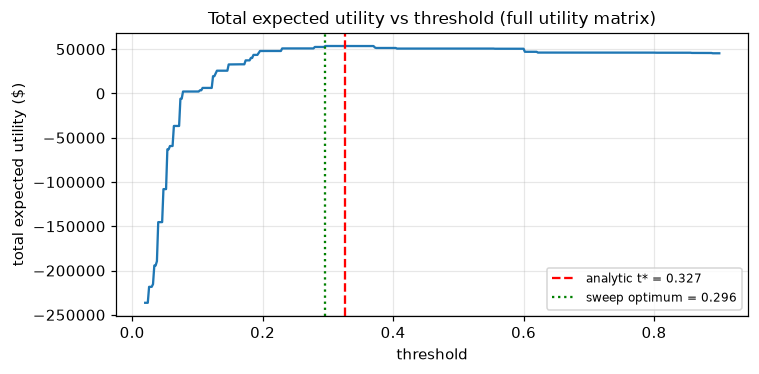

In [21]:
# --- Solution 2 ---
U_TP, U_FP, U_FN, U_TN = 35.0, -15.0, 0.0, 2.0
t_star_full = (U_TN - U_FP) / ((U_TN - U_FP) + (U_TP - U_FN))
print(f"analytic t* = (2+15) / ((2+15) + (35-0)) = {t_star_full:.4f}")


def total_expected_utility(s_decision, thresh):
    target = s_decision >= thresh
    u_target = np.sum(p_te[target] * U_TP + (1 - p_te[target]) * U_FP)
    u_skip = np.sum(p_te[~target] * U_FN + (1 - p_te[~target]) * U_TN)
    return u_target + u_skip


grid = np.linspace(0.02, 0.9, 441)
utils = np.array([total_expected_utility(p_hat, t) for t in grid])
t_emp = grid[np.argmax(utils)]
print(f"sweep optimum       = {t_emp:.4f}   total utility = {utils.max():,.0f}")
print(f"utility at analytic = {total_expected_utility(p_hat, t_star_full):,.0f}")

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(grid, utils, "C0")
ax.axvline(t_star_full, color="red", ls="--", label=f"analytic t* = {t_star_full:.3f}")
ax.axvline(t_emp, color="green", ls=":", label=f"sweep optimum = {t_emp:.3f}")
ax.set(title="Total expected utility vs threshold (full utility matrix)",
       xlabel="threshold", ylabel="total expected utility ($)")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

In [22]:
# --- Solution 3 ---
rng_ds = np.random.default_rng(123)
R_KEEP = 0.2
neg_tr = np.where(y_tr == 0)[0]
pos_tr = np.where(y_tr == 1)[0]
ds_idx = np.concatenate([pos_tr, rng_ds.choice(neg_tr, int(len(neg_tr) * R_KEEP), replace=False)])

lr_ds = Pipeline([
    ("scale", StandardScaler()),
    ("lr", LogisticRegression(max_iter=2000)),
]).fit(X_tr.iloc[ds_idx], y_tr[ds_idx])
s_ds = lr_ds.predict_proba(X_te)[:, 1]

odds_ds = s_ds / (1 - s_ds)
s_fix = (odds_ds * R_KEEP) / (1 + odds_ds * R_KEEP)

sol3 = pd.DataFrame({
    "trained on downsampled": {"mean predicted": s_ds.mean(), "ECE": ece(y_te, s_ds),
                               "ROC-AUC": roc_auc_score(y_te, s_ds)},
    "after prior correction": {"mean predicted": s_fix.mean(), "ECE": ece(y_te, s_fix),
                               "ROC-AUC": roc_auc_score(y_te, s_fix)},
}).T
print(f"downsampled training prevalence: {y_tr[ds_idx].mean():.3f}  "
      f"(true test prevalence {y_te.mean():.3f})")
print(sol3.round(4))
print("\nOdds were inflated by 1/r = 5x by construction; multiplying them back by r restores")
print("calibration analytically — a monotone map, so the ranking (AUC) is untouched. The same")
print("logic (with per-class weights) undoes class_weight='balanced'.")

downsampled training prevalence: 0.350  (true test prevalence 0.102)
                        mean predicted    ECE  ROC-AUC
trained on downsampled          0.3058 0.2040   0.7510
after prior correction          0.0962 0.0128   0.7510

Odds were inflated by 1/r = 5x by construction; multiplying them back by r restores
calibration analytically — a monotone map, so the ranking (AUC) is untouched. The same
logic (with per-class weights) undoes class_weight='balanced'.
